# 05 · Order-volume prediction models
**Owner:** P5 (Prediction Model & Monsoon Lift) · **Tasks:** T25 models, T26 evaluation and first findings ·
**Rubric:** Review 1, predictive model development (4), model evaluation and interpretation (3)

**Question.** Can next-day order volume be predicted from recent orders, the calendar and the weather, and which
inputs matter most?

**Data.** Real Coimbatore weather (`data/raw/weather.csv`) joined to the *synthetic* daily orders from the generator
(`docs/generator.md`). The orders are synthetic by design, so results show how well each model recovers the documented
generator rules, not how a real restaurant behaves.

**Approach.** One-day-ahead prediction. Features use only information known before the predicted day (lagged orders,
calendar) plus that day's weather. Weather is *observed*, not forecast, so accuracy is an upper bound for a live system.
The last 56 days are held out chronologically; hyper-parameters are tuned on the training window only with
`TimeSeriesSplit`. The seasonal-naive baseline repeats the same weekday one week earlier.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import plotstyle, predict
plotstyle.apply()
C = plotstyle.C

# One-line switch if the orders file changes (e.g. a regenerated dataset).
ORDERS_CSV = ROOT / "data/raw/daily_orders.csv"
WEATHER_CSV = ROOT / "data/raw/weather.csv"
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)

## 1. Data and features

In [2]:
daily = predict.load_model_frame(WEATHER_CSV, ORDERS_CSV)
X = predict.make_features(daily)
y = daily["order_count"].loc[X.index]
Xtr, Xte, ytr, yte = predict.split_train_test(X, y)
print(f"{len(daily)} days, {daily.index.min().date()} to {daily.index.max().date()}")
print(f"Features: {X.shape[1]}  |  train {len(Xtr)} days ({Xtr.index.min().date()} to {Xtr.index.max().date()})")
print(f"Test: {len(Xte)} days ({Xte.index.min().date()} to {Xte.index.max().date()})")
print("Features:", ", ".join(X.columns))

1097 days, 2023-09-24 to 2026-09-24
Features: 21  |  train 1034 days (2023-10-01 to 2026-07-30)
Test: 56 days (2026-07-31 to 2026-09-24)
Features: lag1, lag7, roll7, precip_mm, temp_max_c, humidity_mean_pct, is_rainy, heavy_rain, is_hot, is_fri_sun, rain_x_weekend, is_festival, dow_0, dow_1, dow_2, dow_3, dow_4, dow_5, dow_6, phase_sw_monsoon, phase_ne_monsoon


**Feature groups.** Lagged orders (`lag1`, `lag7`, `roll7` = mean of the previous 7 days), same-day weather
(rain, temperature, humidity and the team's rainy/heavy/hot flags), calendar (day of week, Fri-Sun flag, festival
flag from the documented festival calendar) and monsoon phase (south-west Jun-Sep, north-east Oct-Dec).
Lags are shifted so a day never sees its own value.

## 2. Models (T25)

In [3]:
fitted, preds = predict.fit_and_predict(Xtr, ytr, Xte)
for name, params in predict.fit_and_predict.best_params.items():
    print(f"{name:14s} best params: {params}")

Ridge          best params: {'ridge__alpha': 0.1}
Random Forest  best params: {'max_depth': 4, 'min_samples_leaf': 10}
XGBoost        best params: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}


## 3. Evaluation (T26)

In [4]:
overall = predict.score_table(yte, preds)
overall.round(2).to_csv(RESULTS / "model_metrics_overall.csv")
overall.round(2)

,n,R2,MAE,MSE,RMSE,MAPE_%,bias
model,,,,,,,
Seasonal naive,56,-0.56,58.21,5095.75,71.38,36.11,0.50
Ridge,56,0.89,14.88,344.21,18.55,8.69,3.05
Random Forest,56,0.90,14.62,333.79,18.27,8.62,1.80
XGBoost,56,0.90,14.73,329.13,18.14,8.81,2.88


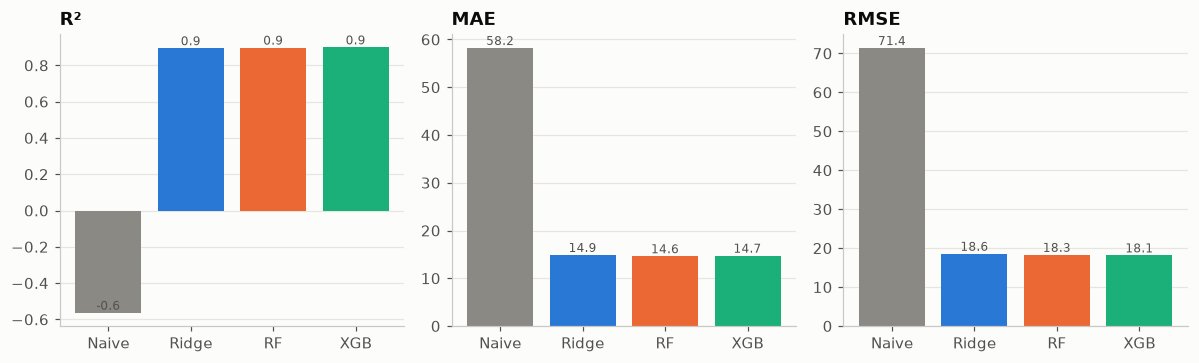

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
colors = [C["gray"], C["blue"], C["orange"], C["aqua"]]
for ax, metric in zip(axes, ["R2", "MAE", "RMSE"]):
    vals = overall[metric]
    ax.bar(range(4), vals.values, color=colors)
    ax.set_xticks(range(4)); ax.set_xticklabels(["Naive", "Ridge", "RF", "XGB"])
    ax.set_title(metric.replace("R2", "R²"))
    for i, v in enumerate(vals.values):
        ax.text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color=C["ink2"])
fig.tight_layout(); fig.savefig(RESULTS / "fig09_model_metrics.png", dpi=150); plt.show()

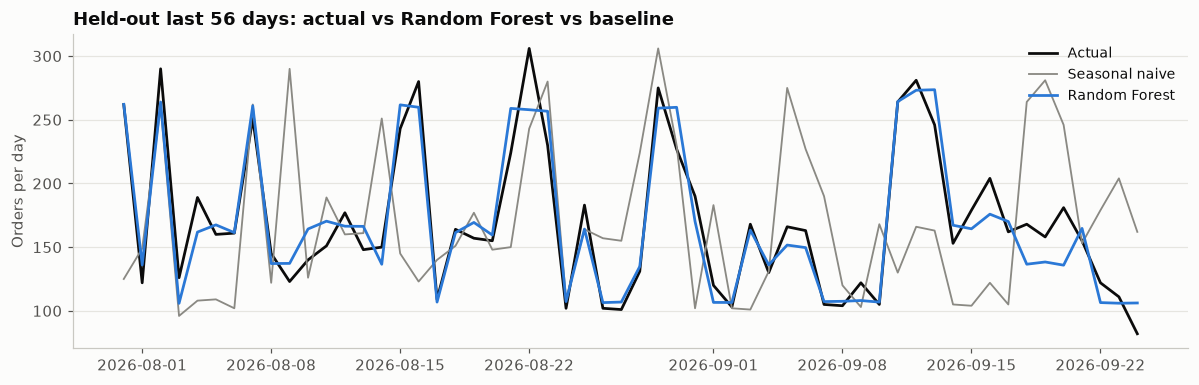

Best model by MAE: Random Forest


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(yte.index, yte, color=C["ink"], label="Actual", lw=1.8)
best = overall["MAE"].drop("Seasonal naive").idxmin()
ax.plot(yte.index, preds["Seasonal naive"], color=C["gray"], lw=1.2, label="Seasonal naive")
ax.plot(yte.index, preds[best], color=C["blue"], lw=1.8, label=best)
ax.set_title(f"Held-out last 56 days: actual vs {best} vs baseline"); ax.set_ylabel("Orders per day"); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS / "fig10_actual_vs_pred.png", dpi=150); plt.show()
print("Best model by MAE:", best)

### Where does each model do well or badly?
Accuracy split by weather regime (rainy / hot / normal days) and by day type. A model that is only good on average can
still be poor on the rainy days the business cares about.

In [7]:
ctx = daily.loc[Xte.index]
seg_regime = predict.score_table(yte, preds, by=ctx["regime"])
seg_regime.round(2).to_csv(RESULTS / "model_metrics_by_regime.csv")
seg_regime.round(2)

n     R2    MAE      MSE   RMSE  MAPE_%  bias
model          segment                                                
Seasonal naive normal   21   0.11  59.95  5477.76  74.01   35.72  9.00
               rainy    29 -11.46  55.86  4772.55  69.08   35.36 -7.38
               hot       6   0.02  63.50  5320.83  72.94   41.10  8.83
Ridge          normal   21   0.93  15.90   412.91  20.32    8.43  1.11
               rainy    29   0.14  14.82   329.51  18.15    9.05  6.47
               hot       6   0.97  11.62   174.76  13.22    7.85 -6.68
Random Forest  normal   21   0.93  15.87   411.67  20.29    8.85 -0.02
               rainy    29   0.19  14.78   310.70  17.63    9.11  3.95
               hot       6   0.97   9.49   172.85  13.15    5.45 -2.24
XGBoost        normal   21   0.93  16.02   401.53  20.04    9.09  0.99
               rainy    29   0.19  14.42   308.62  17.57    8.91  5.68
               hot       6   0.97  11.70   174.86  13.22    7.42 -4.06

In [8]:
day_type = pd.Series(np.where(ctx["dow"].isin([4, 5, 6]), "Fri-Sun", "Mon-Thu"), index=ctx.index)
seg_day = predict.score_table(yte, preds, by=day_type)
seg_day.round(2)

n    R2    MAE      MSE   RMSE  MAPE_%  bias
model          segment                                               
Seasonal naive Fri-Sun  24 -1.31  77.29  8232.21  90.73   40.23 -1.12
               Mon-Thu  32 -1.63  43.91  2743.41  52.38   33.02  1.72
Ridge          Fri-Sun  24  0.85  19.85   548.97  23.43    9.78  3.98
               Mon-Thu  32  0.82  11.16   190.63  13.81    7.88  2.35
Random Forest  Fri-Sun  24  0.85  18.86   517.63  22.75    9.30  3.09
               Mon-Thu  32  0.81  11.44   195.91  14.00    8.11  0.83
XGBoost        Fri-Sun  24  0.86  19.24   516.56  22.73    9.60  4.33
               Mon-Thu  32  0.82  11.35   188.55  13.73    8.23  1.80

### Residuals

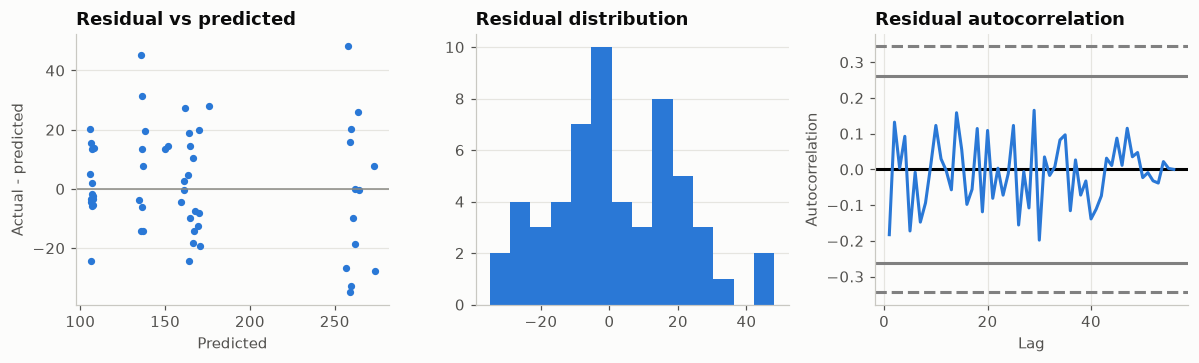

Residual mean 1.80, sd 18.35; Ljung-Box p (lag 7) = 0.439


In [9]:
res = (yte - preds[best])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].scatter(preds[best], res, s=14, color=C["blue"]); axes[0].axhline(0, color=C["gray"], lw=1)
axes[0].set_title("Residual vs predicted"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual - predicted")
axes[1].hist(res, bins=14, color=C["blue"]); axes[1].set_title("Residual distribution")
pd.plotting.autocorrelation_plot(res, ax=axes[2], color=C["blue"]); axes[2].set_title("Residual autocorrelation")
fig.tight_layout(); fig.savefig(RESULTS / "fig11_residuals.png", dpi=150); plt.show()
from statsmodels.stats.diagnostic import acorr_ljungbox
lb = acorr_ljungbox(res, lags=[7], return_df=True)
print(f"Residual mean {res.mean():.2f}, sd {res.std():.2f}; Ljung-Box p (lag 7) = {lb['lb_pvalue'].iloc[0]:.3f}")

### Which inputs matter?
Permutation importance on the held-out set (increase in MAE when one feature is shuffled; model-agnostic and honest
about correlated features), and SHAP values for the XGBoost model.

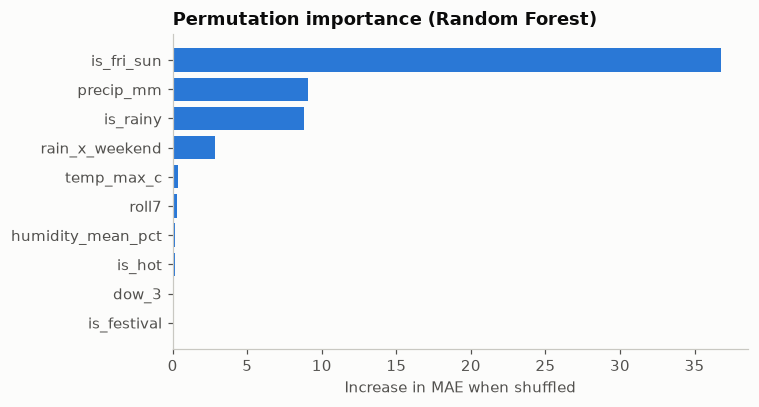

is_fri_sun           36.75
precip_mm             9.06
is_rainy              8.81
rain_x_weekend        2.83
temp_max_c            0.38
roll7                 0.26
humidity_mean_pct     0.17
is_hot                0.14
dow_3                 0.08
is_festival           0.03
dtype: float64

In [10]:
from sklearn.inspection import permutation_importance
model = fitted[best]
pi = permutation_importance(model, Xte, yte, scoring="neg_mean_absolute_error", n_repeats=30, random_state=predict.SEED)
imp = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
imp.round(2).to_csv(RESULTS / "model_feature_importance.csv", header=["MAE_increase"])
top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(top.index, top.values, color=C["blue"]); ax.set_xlabel("Increase in MAE when shuffled")
ax.set_title(f"Permutation importance ({best})"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(RESULTS / "fig12_importance.png", dpi=150); plt.show()
imp.head(10).round(2)

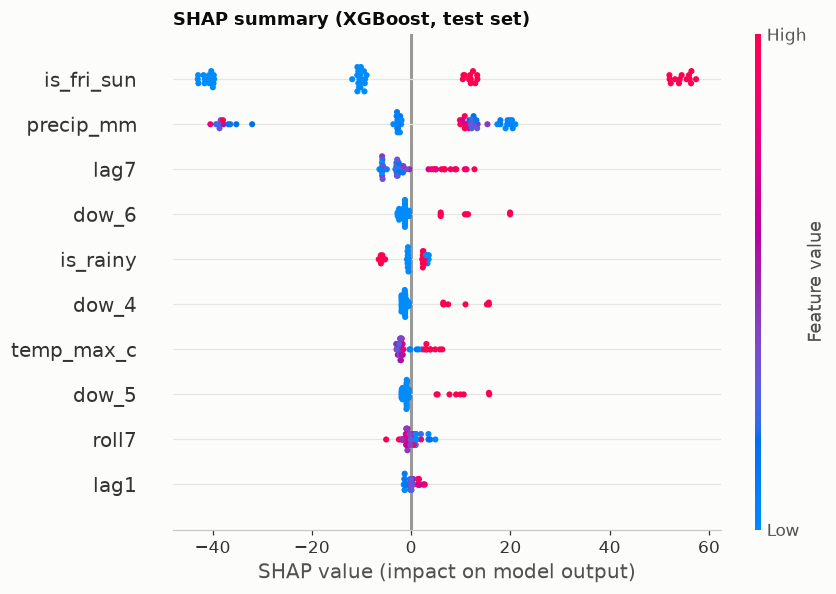

In [11]:
import shap
explainer = shap.TreeExplainer(fitted["XGBoost"])
sv = explainer.shap_values(Xte)
shap.summary_plot(sv, Xte, show=False, max_display=10)
plt.title("SHAP summary (XGBoost, test set)"); plt.tight_layout()
plt.savefig(RESULTS / "fig13_shap.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Effect of weather and the planning view

In [12]:
no_weather_cols = [c for c in X.columns if c not in predict.WEATHER_INPUTS and not c.startswith("phase_")]
_, p_nw = predict.fit_and_predict(Xtr[no_weather_cols], ytr, Xte[no_weather_cols])
rows = []
for m in ["Ridge", "Random Forest", "XGBoost"]:
    rows.append({"model": m, "MAE with weather": predict.score(yte, preds[m])["MAE"],
                 "MAE without weather": predict.score(yte, p_nw[m])["MAE"]})
weather_effect = pd.DataFrame(rows).set_index("model")
weather_effect["improvement_%"] = (1 - weather_effect["MAE with weather"] / weather_effect["MAE without weather"]) * 100
weather_effect.round(2).to_csv(RESULTS / "model_weather_effect.csv")
weather_effect.round(2)

,MAE with weather,MAE without weather,improvement_%
model,,,
Ridge,14.88,41.52,64.16
Random Forest,14.62,36.21,59.62
XGBoost,14.73,36.80,59.97


In [13]:
q90 = float(res.abs().quantile(0.90))
print(f"{best}: on 90% of held-out days the prediction was within +/- {q90:.0f} orders "
      f"({q90 / yte.mean() * 100:.0f}% of the mean daily volume of {yte.mean():.0f}).")

Random Forest: on 90% of held-out days the prediction was within +/- 28 orders (16% of the mean daily volume of 170).


In [14]:
# Noise floor implied by the generator: daily counts are Negative Binomial around the generator's own expected value,
# with dispersion r = outlets x per-outlet r (fitted on the real Swiggy days). Even a model that knew the expected value
# could not beat RMSE = sqrt(mean(mu + mu^2 / r)) on these days.
import calibration, generator
R_DISP = generator.OUTLETS * calibration.calibrate().dispersion_r
mu = pd.read_csv(ORDERS_CSV, parse_dates=["date"]).set_index("date")["expected_orders"].reindex(yte.index)
floor_rmse = float(np.sqrt((mu + mu**2 / R_DISP).mean()))
print(f"Irreducible RMSE on the test days (r = {R_DISP:.0f}): {floor_rmse:.1f}  vs best-model RMSE {overall.loc[best, 'RMSE']:.1f}")

Irreducible RMSE on the test days (r = 138): 19.9  vs best-model RMSE 18.3


## 5. First findings
1. **Every model beats the baseline by a wide margin.** On the 56 held-out days Random Forest has MAE 14.6, XGBoost 14.7 and
   Ridge 14.9, against 58.2 for the seasonal-naive baseline (about 75% lower); R² is 0.89-0.90. The three models are within
   0.3 orders of each other, so the model family matters much less than the inputs.
2. **Weather is a major driver, once the model sees how it works.** Removing every weather input (including the monsoon
   phases) raises MAE by 60-64% for all three models. Rain lifts weekday orders and lowers weekend orders (real Swiggy
   evidence, `docs/generator.md`), so the `rain_x_weekend` feature is essential: without it Ridge cannot represent the
   effect at all. Permutation importance: Fri-Sun +36.8 MAE when shuffled, precipitation +9.1, rainy flag +8.8,
   rain x weekend +2.8.
3. **Errors are at the noise floor.** Daily counts are drawn as Negative Binomial around the generator's expected value
   (r = 138), so even a perfect model would have RMSE of about 19.9 on these days. The best model's RMSE is 18.3 - within
   sampling noise of that floor - so more tuning cannot help.
4. **Yesterday's orders barely help.** `lag1`, `lag7` and `roll7` have near-zero importance because the generator has no
   day-to-day memory. Real restaurant data would normally have it, so this should not be generalised.
5. **Business reading.** Plan staffing and stock from the day type and the rain forecast together. On 90% of held-out days
   the prediction was within about 28 orders (16% of the mean daily volume of 170).

**Limits.**
- Rainy test days have R² of only about 0.2 because rain compresses volume into a narrow band (low variance to explain);
  their MAE (14.4-14.8) is as good as on other days.
- The hot-day segment has only 6 test days, too few to compare models there.
- Weather is observed, not forecast, so these errors are an upper bound on what a live system could achieve.
- Results come from one chronological split.